In [1]:
%pip install kagglehub --quiet

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import os

dataset_path = '/kaggle/input/brain-tumor-mri-dataset'

# трансформации
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# данные
train_dataset = datasets.ImageFolder(root=os.path.join(dataset_path, 'Training'), transform=transform)
test_dataset  = datasets.ImageFolder(root=os.path.join(dataset_path, 'Testing'),  transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

print(f"Классы: {train_dataset.classes}")
print(f"Картинок в train: {len(train_dataset)}, в test: {len(test_dataset)}")

# устройство
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Картинок в train: 5600, в test: 1600
Устройство: cpu


**Создание** **CNN**

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# создание модели
simple_model = SimpleCNN(num_classes=4).to(device)
print(simple_model)

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=32768, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=4, bias=True)
)


**SimpleCNN обучение**


In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(simple_model.parameters(), lr=0.001)

epochs = 5
simple_train_losses, simple_test_losses = [], []
simple_train_accs, simple_test_accs = [], []

for epoch in range(epochs):
    # обучение
    simple_model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = simple_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    simple_train_losses.append(running_loss / total)
    simple_train_accs.append(correct / total)

    # тест
    simple_model.eval()
    test_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = simple_model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    simple_test_losses.append(test_loss / total)
    simple_test_accs.append(correct / total)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {simple_train_losses[-1]:.4f} | "
          f"Test Loss: {simple_test_losses[-1]:.4f} | "
          f"Test Acc: {simple_test_accs[-1]:.4f}")

Epoch 1/5 | Train Loss: 0.0261 | Test Loss: 1.7327 | Test Acc: 0.8681
Epoch 2/5 | Train Loss: 0.0097 | Test Loss: 1.5356 | Test Acc: 0.8838
Epoch 3/5 | Train Loss: 0.0007 | Test Loss: 1.8556 | Test Acc: 0.8931
Epoch 4/5 | Train Loss: 0.0002 | Test Loss: 1.9325 | Test Acc: 0.8962
Epoch 5/5 | Train Loss: 0.0001 | Test Loss: 1.9959 | Test Acc: 0.8969


**ResNet18**

In [9]:
import torchvision.models as models

# предобученная ResNet18
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# заморозка слоев
for param in resnet.parameters():
    param.requires_grad = False

# замена слоя
num_features = resnet.fc.in_features
resnet.fc = nn.Linear(num_features, 4)

resnet = resnet.to(device)
print(resnet.fc)

Linear(in_features=512, out_features=4, bias=True)


**Обучение** **ResNet**

In [11]:
optimizer_resnet = optim.Adam(resnet.fc.parameters(), lr=0.001)

epochs = 5
resnet_train_losses, resnet_test_losses = [], []
resnet_train_accs, resnet_test_accs = [], []

for epoch in range(epochs):
    # обучение
    resnet.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_resnet.zero_grad()
        outputs = resnet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_resnet.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    resnet_train_losses.append(running_loss / total)
    resnet_train_accs.append(correct / total)

    # тест
    resnet.eval()
    test_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = resnet(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    resnet_test_losses.append(test_loss / total)
    resnet_test_accs.append(correct / total)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {resnet_train_losses[-1]:.4f} | "
          f"Test Loss: {resnet_test_losses[-1]:.4f} | "
          f"Test Acc: {resnet_test_accs[-1]:.4f}")

Epoch 1/5 | Train Loss: 0.3390 | Test Loss: 0.5816 | Test Acc: 0.8119
Epoch 2/5 | Train Loss: 0.3404 | Test Loss: 0.5919 | Test Acc: 0.8263
Epoch 3/5 | Train Loss: 0.3278 | Test Loss: 0.5718 | Test Acc: 0.8131
Epoch 4/5 | Train Loss: 0.3173 | Test Loss: 0.5551 | Test Acc: 0.8137
Epoch 5/5 | Train Loss: 0.3056 | Test Loss: 0.5668 | Test Acc: 0.8187


**Визуализация**

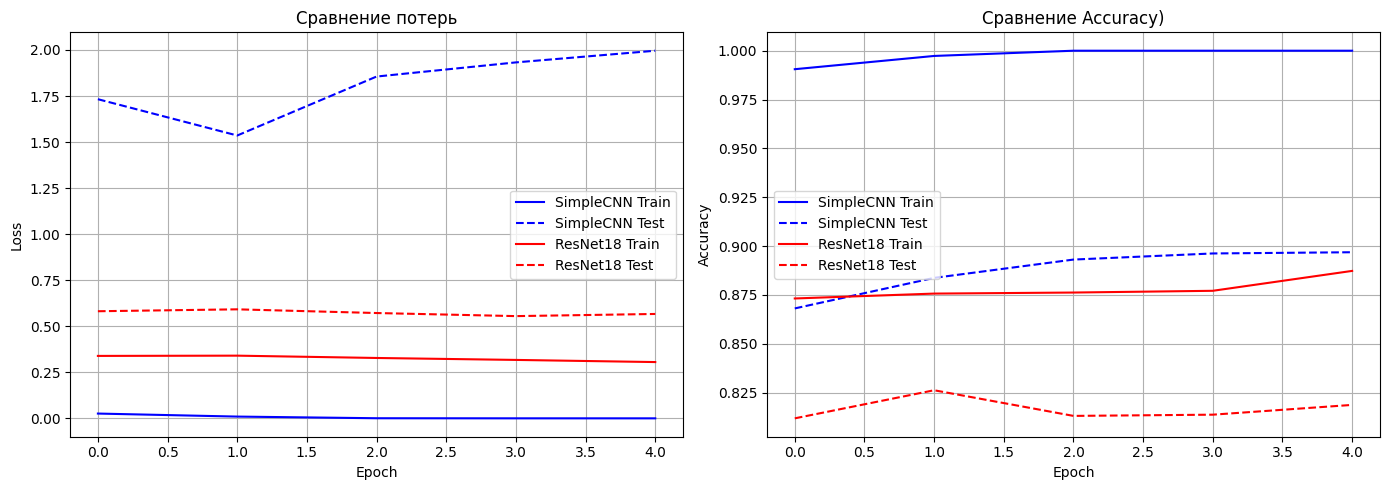


Итоговое сравнение
SimpleCNN  — Test Accuracy: 0.8969
ResNet18   — Test Accuracy: 0.8187


In [12]:
plt.figure(figsize=(14, 5))

# график потерь
plt.subplot(1, 2, 1)
plt.plot(simple_train_losses, label='SimpleCNN Train', color='blue')
plt.plot(simple_test_losses, label='SimpleCNN Test', color='blue', linestyle='--')
plt.plot(resnet_train_losses, label='ResNet18 Train', color='red')
plt.plot(resnet_test_losses, label='ResNet18 Test', color='red', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Сравнение потерь')
plt.legend()
plt.grid(True)

# график точности
plt.subplot(1, 2, 2)
plt.plot(simple_train_accs, label='SimpleCNN Train', color='blue')
plt.plot(simple_test_accs, label='SimpleCNN Test', color='blue', linestyle='--')
plt.plot(resnet_train_accs, label='ResNet18 Train', color='red')
plt.plot(resnet_test_accs, label='ResNet18 Test', color='red', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Сравнение Accuracy)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("Итоговое сравнение")
print("="*50)
print(f"SimpleCNN  — Test Accuracy: {simple_test_accs[-1]:.4f}")
print(f"ResNet18   — Test Accuracy: {resnet_test_accs[-1]:.4f}")

**Предсказания**

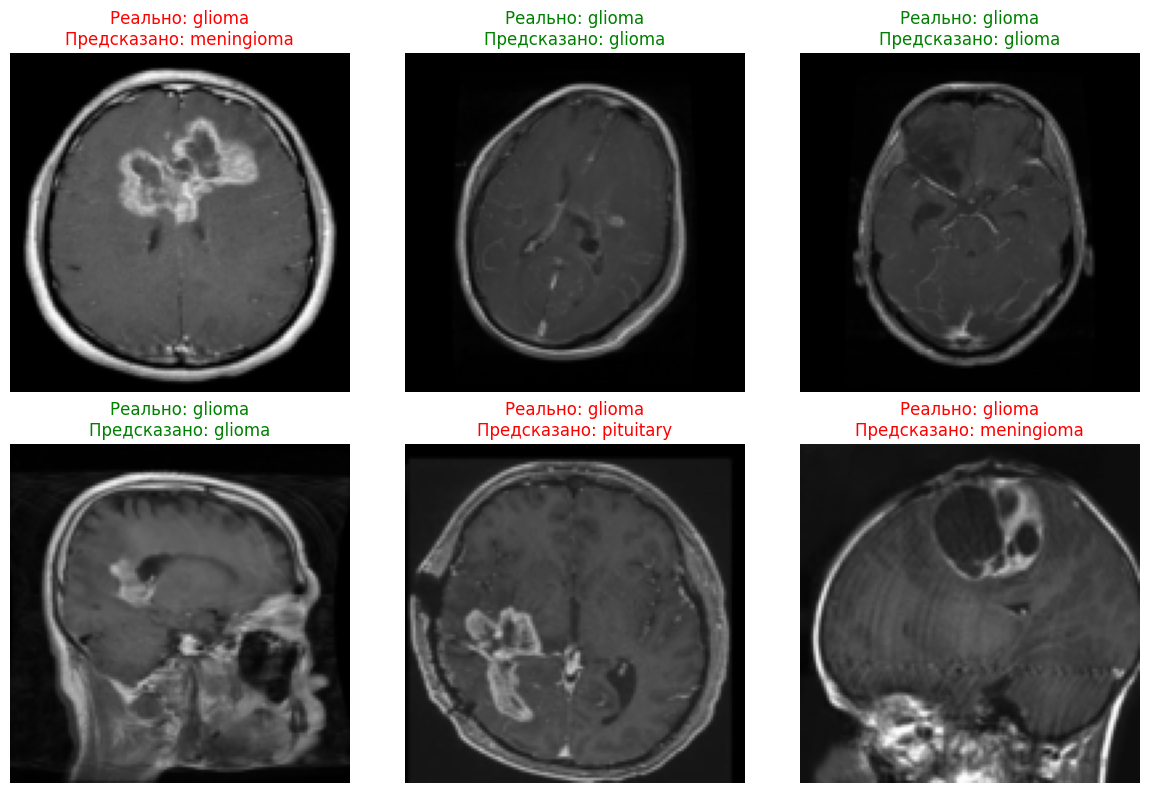

In [13]:
import numpy as np

# один батч из текста
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

# предсказание ResNet
resnet.eval()
with torch.no_grad():
    outputs = resnet(images)
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().numpy().transpose(1, 2, 0)
    img = (img * 0.5) + 0.5
    ax.imshow(img)
    real = train_dataset.classes[labels[i].item()]
    pred = train_dataset.classes[preds[i].item()]
    color = 'green' if real == pred else 'red'
    ax.set_title(f"Реально: {real}\nПредсказано: {pred}", color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()